In [1]:
import os
import json
import copy
import torch
import torchsparse
import scipy.sparse as sp
import numpy as np
import pickle as pkl
import pandas as pd
import random
from tqdm import tqdm
from sklearn.manifold import TSNE
import torch.nn as nn
import torch.nn.functional as F
# import torch_scatter
import matplotlib.pyplot as plt
import torch_geometric.transforms as T
from torch_geometric.data import Data, OnDiskDataset
from torch_geometric.nn import GATConv, SAGEConv, GCNConv
from torch_geometric.nn.aggr import Aggregation, SumAggregation
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.typing import torch_scatter
from sklearn.utils.multiclass import unique_labels
from sklearn.feature_extraction.text import HashingVectorizer, TfidfVectorizer

In [2]:
def visualize(h, color):
    z = TSNE(n_components=2).fit_transform(h.detach().cpu().numpy())

    plt.figure(figsize=(10,10))
    plt.xticks([])
    plt.yticks([])

    plt.scatter(z[:, 0], z[:, 1], s=70, c=color, cmap="Set2")
    plt.show()

In [3]:
ptype = "is_casecontrol"

In [4]:
with open("../data/x_tensor_sample.pkl", "rb") as f:
    x_tensor = pkl.load(f)

In [5]:
with open("../data/pmid2node_id_sample.json", "r") as f:
    pmid2node_id = json.load(f)

In [6]:
PMIDS = '../data/pmids.pkl'    
with open(PMIDS, 'rb') as f:
    pmids = pkl.load(f)

In [7]:
with open(f"../data/edge_index_sample.pkl", "rb") as f:
    edge_index = pkl.load(f)

In [8]:
num_nodes = len(pmid2node_id)

In [9]:
train_mask = [False for _ in range(num_nodes)]
val_mask = [False for _ in range(num_nodes)]
test_mask = [False for _ in range(num_nodes)]

In [11]:
train_pmids = pmids[ptype]['pos']['train'] + pmids[ptype]['neg']['train']
val_pmids = pmids[ptype]['pos']['val'] + pmids[ptype]['neg']['val']
test_pmids = pmids[ptype]['pos']['test'] + pmids[ptype]['neg']['test']

In [53]:
data = data.to("cuda")
data.test_mask

tensor([False, False, False,  ..., False, False, False], device='cuda:0')

In [49]:
from sklearn.model_selection import RepeatedKFold
rkf = RepeatedKFold(n_splits=10, n_repeats=1, random_state=1)
for train_idx, val_idx in rkf.split(train_pmids):
    print(len([train_pmids[i] for i in train_idx]))
    print(len([train_pmids[i] for i in val_idx]))

7200
800
7200
800
7200
800
7200
800
7200
800
7200
800
7200
800
7200
800
7200
800
7200
800


In [12]:
train_set_size = 0
for pmid in train_pmids:
    if str(pmid) in pmid2node_id:
        node_id = pmid2node_id[str(pmid)]
        train_mask[node_id] = True
        train_set_size +=1

In [13]:
val_set_size = 0
for pmid in val_pmids:
    if str(pmid) in pmid2node_id:
        node_id = pmid2node_id[str(pmid)]
        val_mask[node_id] = True
        val_set_size +=1

In [14]:
test_set_size = 0
for pmid in test_pmids:
    if str(pmid) in pmid2node_id:
        node_id = pmid2node_id[str(pmid)]
        test_mask[node_id] = True
        test_set_size+=1

In [15]:
train_set_size

6866

In [16]:
val_set_size

6862

In [17]:
test_set_size

6822

In [18]:
train_mask = torch.tensor(train_mask, dtype=torch.bool)
val_mask = torch.tensor(val_mask, dtype=torch.bool)
test_mask = torch.tensor(test_mask, dtype=torch.bool)

In [19]:
y = [-1 for _ in range(num_nodes)]

In [20]:
pos_pmids = pmids[ptype]['pos']['train'] + pmids[ptype]['pos']['val'] + pmids[ptype]['pos']['test']
neg_pmids = pmids[ptype]['neg']['train'] + pmids[ptype]['neg']['val'] + pmids[ptype]['neg']['test']

In [21]:
num_pos = 0
for pmid in pos_pmids:
    if str(pmid) in pmid2node_id:
        node_id = pmid2node_id[str(pmid)]
        y[node_id] = 1
        num_pos +=1

In [22]:
num_pos

10302

In [23]:
num_neg = 0
for pmid in neg_pmids:
    if str(pmid) in pmid2node_id:
        node_id = pmid2node_id[str(pmid)]
        y[node_id] = 0
        num_neg +=1

In [24]:
y = torch.tensor(y, dtype=torch.long)

In [25]:
edge_index = torch.tensor(edge_index)

/tmp/ipykernel_313647/475849734.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  edge_index = torch.tensor(edge_index)


In [26]:
data = Data(x=torch.tensor(x_tensor, dtype=torch.float32), y=y, edge_index=edge_index, train_mask=train_mask, val_mask=val_mask, test_mask=test_mask)

In [27]:
indices = data.train_mask

tensor([False,  True, False,  ..., False, False, False])

In [84]:
del y
del x_tensor
del edge_index
del train_mask
del val_mask
del test_mask

In [85]:
data

Data(x=[111306, 5000], edge_index=[2, 50822], y=[111306], train_mask=[111306], val_mask=[111306], test_mask=[111306])

In [86]:
num_classes = 2
class GAT(torch.nn.Module):
    def __init__(self):
        super(GAT, self).__init__()
        self.hid = 1
        self.in_head = 1
        self.out_head = 1
        
        
        self.conv1 = GATConv(data.num_features, self.hid, heads=self.in_head, dropout=0.6)
        self.conv2 = GATConv(self.hid*self.in_head, num_classes, concat=False,
                             heads=self.out_head, dropout=0.6)
#         self.conv = GATConv(data.num_features, num_classes, concat=True,
#                              heads=self.out_head, dropout=0.6)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
                
        x = F.dropout(x, p=0.6, training=self.training)
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=0.6, training=self.training)
        x = self.conv2(x, edge_index)
#         x = self.conv(x, edge_index)
        
        return F.log_softmax(x, dim=1)

In [87]:
class Net(torch.nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        
        self.conv = SAGEConv(data.num_features,
                             num_classes,
                             aggr=SumAggregation()) # max, mean, add ...)

    def forward(self, data):
        x = self.conv(data.x, data.edge_index)
        return F.log_softmax(x, dim=1)
    
# class Net(torch.nn.Module):
#     def __init__(self):
#         super(Net, self).__init__()
        
#         self.conv = SAGEConv(data.num_features,
#                              num_classes,
#                              aggr='max') # max, mean, add ...)

#     def forward(self, data):
#         x = self.conv(data.x, data.edge_index)
#         return F.log_softmax(x, dim=1)
    

In [88]:
class GCN(torch.nn.Module):
    def __init__(self, hidden_channels):
        super().__init__()
        torch.manual_seed(1234567)
        self.conv1 = GCNConv(data.num_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, num_classes)

    def forward(self, data):
        x = self.conv1(data.x, data.edge_index)
        x = x.relu()
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, data.edge_index)
        return x

In [89]:
data.x

tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000, -0.0312,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        ...,
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]])

In [95]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [96]:
data = data.to(device)

In [97]:
model = Net().to(device)

In [93]:
# model.eval()
# out = model(data)

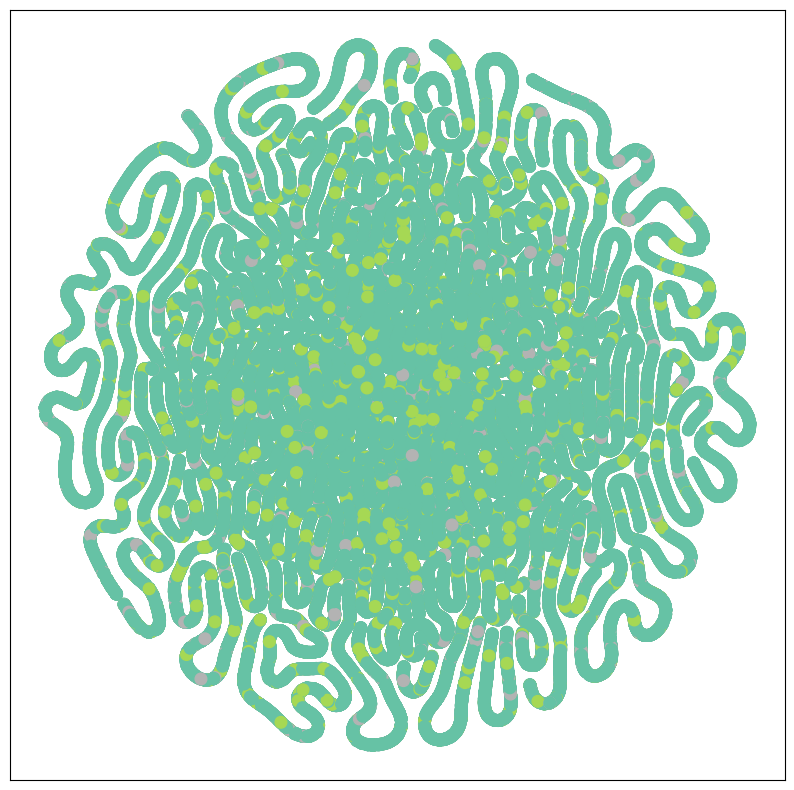

In [43]:
# visualize(out, color=data.y.detach().cpu())

In [102]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
criterion = torch.nn.CrossEntropyLoss()

def train():
      model.train()
      optimizer.zero_grad()  # Clear gradients.
      out = model(data)  # Perform a single forward pass.
      loss = criterion(out[data.train_mask], data.y[data.train_mask])  # Compute the loss solely based on the training nodes.
      loss.backward()  # Derive gradients.
      optimizer.step()  # Update parameters based on gradients.
      return loss

def test():
      model.eval()
      out = model(data)
      pred = out.argmax(dim=1)  # Use the class with highest probability.
      test_correct = pred[data.test_mask] == data.y[data.test_mask]  # Check against ground-truth labels.
      test_acc = int(test_correct.sum()) / int(data.test_mask.sum())  # Derive ratio of correct predictions.
      return test_acc


for epoch in range(1, 500):
    loss = train()
    print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}')

Epoch: 001, Loss: 0.3625
Epoch: 002, Loss: 0.3631
Epoch: 003, Loss: 0.3621
Epoch: 004, Loss: 0.3617
Epoch: 005, Loss: 0.3617
Epoch: 006, Loss: 0.3620
Epoch: 007, Loss: 0.3619
Epoch: 008, Loss: 0.3617
Epoch: 009, Loss: 0.3614
Epoch: 010, Loss: 0.3612
Epoch: 011, Loss: 0.3611
Epoch: 012, Loss: 0.3611
Epoch: 013, Loss: 0.3612
Epoch: 014, Loss: 0.3611
Epoch: 015, Loss: 0.3610
Epoch: 016, Loss: 0.3608
Epoch: 017, Loss: 0.3607
Epoch: 018, Loss: 0.3606
Epoch: 019, Loss: 0.3606
Epoch: 020, Loss: 0.3606
Epoch: 021, Loss: 0.3605
Epoch: 022, Loss: 0.3604
Epoch: 023, Loss: 0.3603
Epoch: 024, Loss: 0.3602
Epoch: 025, Loss: 0.3601
Epoch: 026, Loss: 0.3600
Epoch: 027, Loss: 0.3600
Epoch: 028, Loss: 0.3599
Epoch: 029, Loss: 0.3599
Epoch: 030, Loss: 0.3598
Epoch: 031, Loss: 0.3597
Epoch: 032, Loss: 0.3596
Epoch: 033, Loss: 0.3596
Epoch: 034, Loss: 0.3596
Epoch: 035, Loss: 0.3595
Epoch: 036, Loss: 0.3595
Epoch: 037, Loss: 0.3594
Epoch: 038, Loss: 0.3594
Epoch: 039, Loss: 0.3593
Epoch: 040, Loss: 0.3593


Epoch: 333, Loss: 0.3567
Epoch: 334, Loss: 0.3567
Epoch: 335, Loss: 0.3567
Epoch: 336, Loss: 0.3567
Epoch: 337, Loss: 0.3567
Epoch: 338, Loss: 0.3567
Epoch: 339, Loss: 0.3567
Epoch: 340, Loss: 0.3567
Epoch: 341, Loss: 0.3567
Epoch: 342, Loss: 0.3567
Epoch: 343, Loss: 0.3567
Epoch: 344, Loss: 0.3567
Epoch: 345, Loss: 0.3567
Epoch: 346, Loss: 0.3567
Epoch: 347, Loss: 0.3567
Epoch: 348, Loss: 0.3567
Epoch: 349, Loss: 0.3567
Epoch: 350, Loss: 0.3567
Epoch: 351, Loss: 0.3567
Epoch: 352, Loss: 0.3567
Epoch: 353, Loss: 0.3567
Epoch: 354, Loss: 0.3567
Epoch: 355, Loss: 0.3567
Epoch: 356, Loss: 0.3567
Epoch: 357, Loss: 0.3567
Epoch: 358, Loss: 0.3567
Epoch: 359, Loss: 0.3567
Epoch: 360, Loss: 0.3567
Epoch: 361, Loss: 0.3567
Epoch: 362, Loss: 0.3567
Epoch: 363, Loss: 0.3567
Epoch: 364, Loss: 0.3567
Epoch: 365, Loss: 0.3567
Epoch: 366, Loss: 0.3567
Epoch: 367, Loss: 0.3567
Epoch: 368, Loss: 0.3567
Epoch: 369, Loss: 0.3567
Epoch: 370, Loss: 0.3567
Epoch: 371, Loss: 0.3567
Epoch: 372, Loss: 0.3567


In [103]:
test_acc = test()
print(f'Test Accuracy: {test_acc:.4f}')

Test Accuracy: 0.8336


In [104]:
model.eval()
out = model(data)

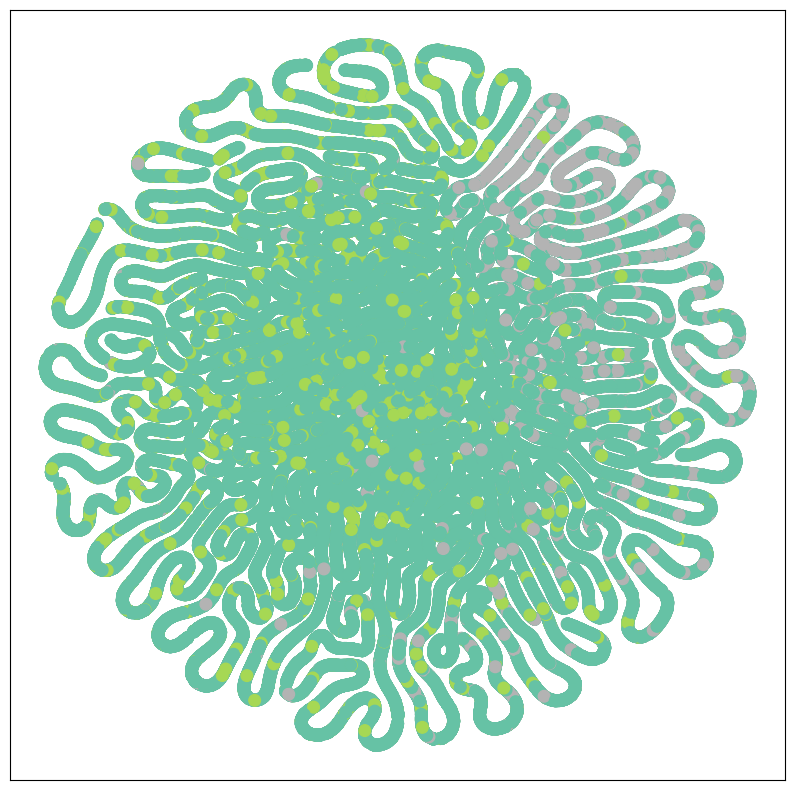

In [105]:
visualize(out, color=data.y.detach().cpu())